In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import json

from sdt_utils_and_logodds import minimal_pc_change, delta_p_for_fixed_logoddsincrease
from utils import read_info

sns.set_context('paper')

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }
N = 18 # for all image sets the number of stimuli was 18

In [2]:
obs = 'P2'
criterion = 'LogOdds'
#min_dprime_delta = 0.1288
#pval_thr = 0.05

In [3]:
d=[]
for image_set in ['taxonomic', 'action', 'greebles']:
    for task in ['odd one out', 'classic', 'odd-one-out-oneoftwo']:
        t, _, _ = read_info(obs, task, image_set)
        d.append(t)

triplet_acc_all = pd.concat(d)

In [4]:
triplet_acc_all

,triplet accuracy,dimension,observer,image_set,task
0,0.882172,1.0,P2,taxonomic,odd one out
1,0.887295,1.0,P2,taxonomic,odd one out
2,0.891393,1.0,P2,taxonomic,odd one out
3,0.897541,1.0,P2,taxonomic,odd one out
4,0.885246,1.0,P2,taxonomic,odd one out
...,...,...,...,...,...
745,0.923711,5.0,P2,greebles,odd-one-out-oneoftwo
746,0.917526,5.0,P2,greebles,odd-one-out-oneoftwo
747,0.923711,5.0,P2,greebles,odd-one-out-oneoftwo
748,0.911340,5.0,P2,greebles,odd-one-out-oneoftwo


In [5]:
def read_recalculated(obs, task, image_set):
    fname = f"../data/triplet_accuracy_vs_dimensionality-{obs}-{task}-{image_set}_LogOdds.json"
    with open(fname, 'r') as f:
        recalculated = json.loads(f.read())
    return recalculated

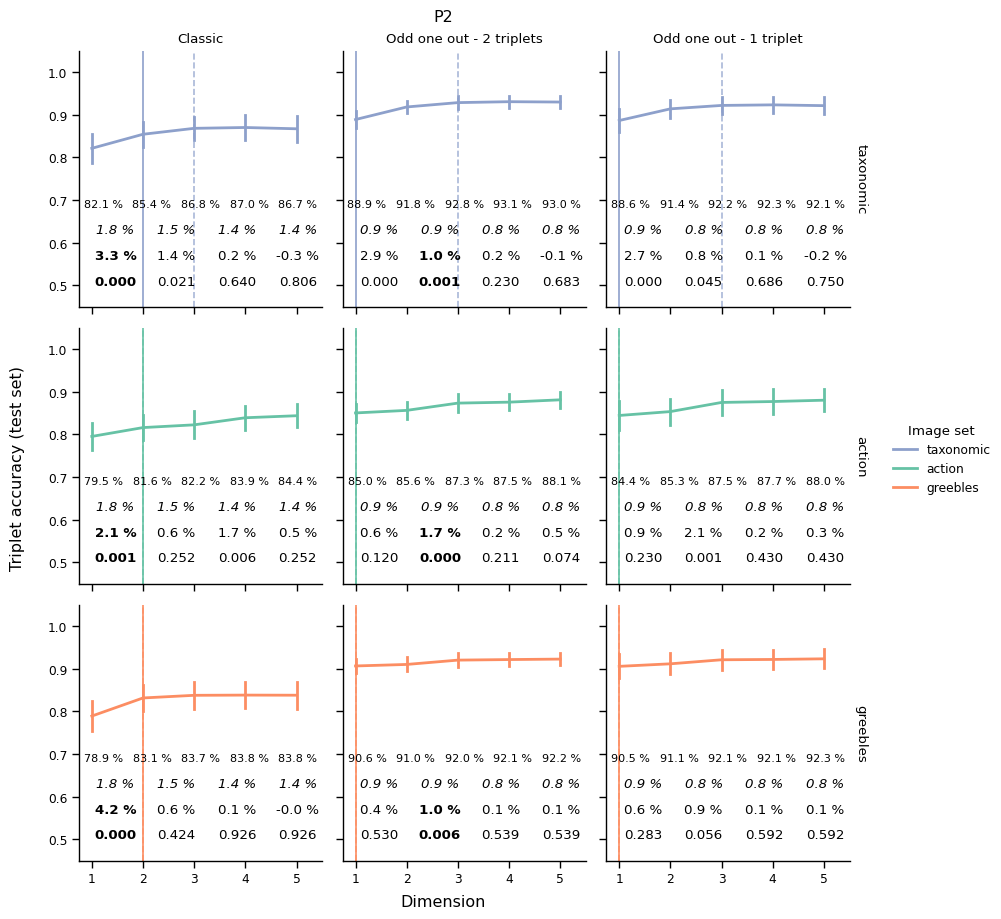

In [6]:
g = sns.FacetGrid(
    data=triplet_acc_all, col="task", row='image_set', 
    hue="image_set", palette=palette_imset,
    col_order = ['classic', 'odd one out', 'odd-one-out-oneoftwo'],
    height=3, margin_titles=True, aspect=1,
    sharey=True, sharex=True,
)

g.map(sns.lineplot, 'dimension', 'triplet accuracy', err_style="bars", errorbar=("sd", 2), 
      linewidth=2, err_kws={'elinewidth': 2})

for (imset, task), ax in g.axes_dict.items():

    ## info from JSON, contain only cblearn output
    _, info, test_scores = read_info(obs, task, imset)
    estimated_dimension = info['estimated_dimension']

    # drawing vertical dashed line with estimated dimensionality as done by cblearn
    ax.axvline(x=estimated_dimension, color=palette_imset[imset], alpha=0.75, zorder=-1,
             linestyle='--')

    ## reading final dimensionality 
    recalculated = read_recalculated(obs, task, image_set)
    new_dimension = recalculated['estimated_dimension']
    reject = recalculated['reject']
    min_delta = recalculated['min_delta']
    
    # drawing vertical dashed line with NEW estimated dimensionality
    ax.axvline(x=new_dimension, color=palette_imset[imset], alpha=1, zorder=2,
             linestyle='-')
    
    ##
    # annotating pvalues (cblearn)
    pvals_corrected = np.array(info['stats_results']['pvals_corrected'])

    # calculating effect size manually from differences
    mean_effect_size = np.mean(np.diff(test_scores, axis=0), axis=1)    
    mean_test_scores = np.mean(test_scores, axis=1)

    for d in range(5):     
        ax.annotate(f"{mean_test_scores[d]*100:.1f} %",
                xy=(0.1+0.2*d, 0.4), xycoords='axes fraction',  fontsize=8,
                xytext=(0.1+0.2*d, 0.4), weight=None, #style='italic', 
                horizontalalignment='center', verticalalignment='center')

    for d in range(4):        
        if reject[d]:
            weight='bold'
        else:
            weight = None
            
       
        ax.annotate(f"{min_delta[d]*100:.1f} %",
                xy=(0.15+0.25*d, 0.3), xycoords='axes fraction',
                xytext=(0.15+0.25*d, 0.3), weight=None, style='italic', 
                horizontalalignment='center', verticalalignment='center')

        ax.annotate(f"{mean_effect_size[d]*100:.1f} %",
                xy=(0.15+0.25*d, 0.2), xycoords='axes fraction',
                xytext=(0.15+0.25*d, 0.2), weight=weight,
                horizontalalignment='center', verticalalignment='center')

        ax.annotate(f"{pvals_corrected[d]:.3f}",
                xy=(0.15+0.25*d, 0.1), xycoords='axes fraction',
                xytext=(0.15+0.25*d, 0.1), weight=weight,
                horizontalalignment='center', verticalalignment='center')



g.set(ylim = (0.45, 1.05), xlim=(0.75, 5.5))
g.add_legend(title = 'Image set')
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.set_ylabels('')
g.set_xlabels('')
g.axes[0][0].set_title('Classic')
g.axes[0][1].set_title('Odd one out - 2 triplets')
g.axes[0][2].set_title('Odd one out - 1 triplet')
g.fig.suptitle(obs, x=0.45, y=1.01)
g.fig.supylabel('Triplet accuracy (test set)')
g.fig.supxlabel('Dimension', x=0.45)
g.savefig(f"../plots/triplet_accuracy_vs_dimensions_{obs}_annotated.pdf")

In [7]:
# plot without annnotations

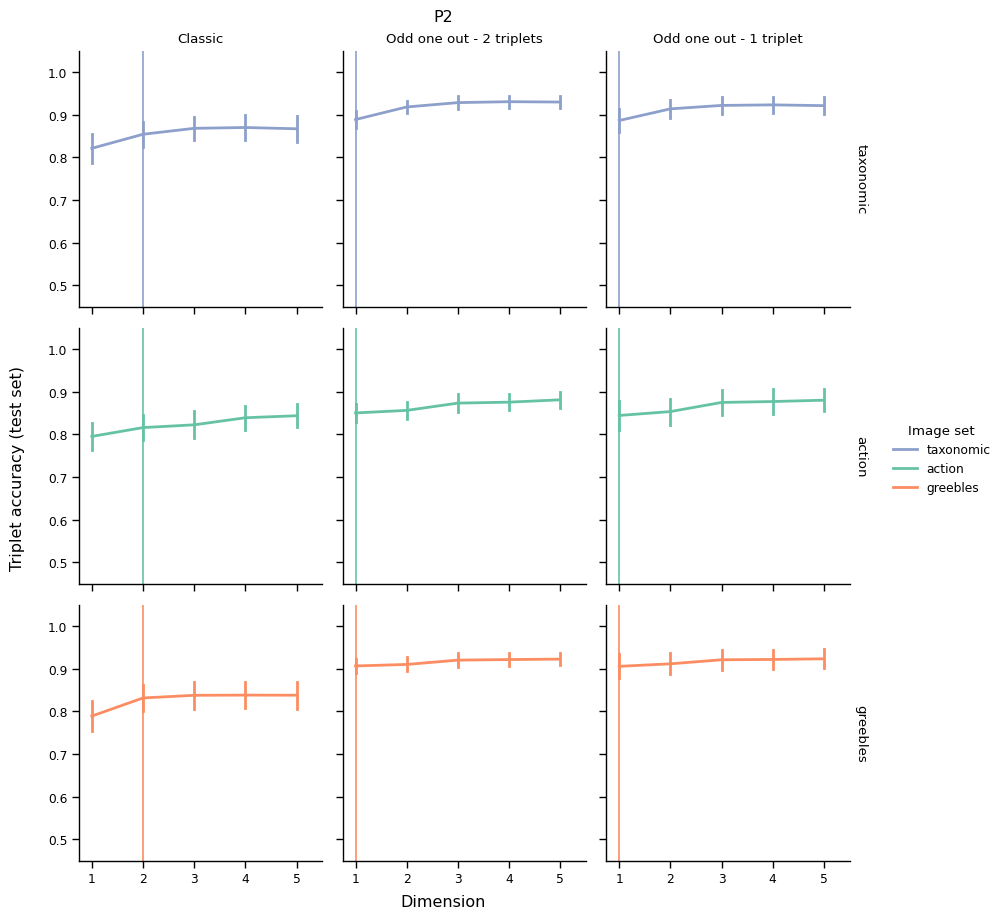

In [8]:
g = sns.FacetGrid(
    data=triplet_acc_all, col="task", row='image_set', 
    hue="image_set", palette=palette_imset,
    col_order = ['classic', 'odd one out', 'odd-one-out-oneoftwo'],
    height=3, margin_titles=True, aspect=1,
    sharey=True, sharex=True,
)

g.map(sns.lineplot, 'dimension', 'triplet accuracy', err_style="bars", errorbar=("sd", 2), 
      linewidth=2, err_kws={'elinewidth': 2})

for (imset, task), ax in g.axes_dict.items():
    
    ## reading final dimensionality 
    recalculated = read_recalculated(obs, task, image_set)
    new_dimension = recalculated['estimated_dimension']

    
    # drawing vertical dashed line with NEW estimated dimensionality
    ax.axvline(x=new_dimension, color=palette_imset[imset], alpha=1, zorder=-1,
             linestyle='-')
   

g.set(ylim = (0.45, 1.05), xlim=(0.75, 5.5))
g.add_legend(title = 'Image set')
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.set_ylabels('')
g.set_xlabels('')
g.axes[0][0].set_title('Classic')
g.axes[0][1].set_title('Odd one out - 2 triplets')
g.axes[0][2].set_title('Odd one out - 1 triplet')
g.fig.suptitle(obs, x=0.45, y=1.01)
g.fig.supylabel('Triplet accuracy (test set)')
g.fig.supxlabel('Dimension', x=0.45)
g.savefig(f"../plots/triplet_accuracy_vs_dimensions_{obs}_ood.pdf")

In [9]:
# plotting with only 'normal' odd one out
mask = triplet_acc_all['task'].isin(set(['classic', 'odd one out']))
triplet_acc_all_plot = triplet_acc_all[mask]

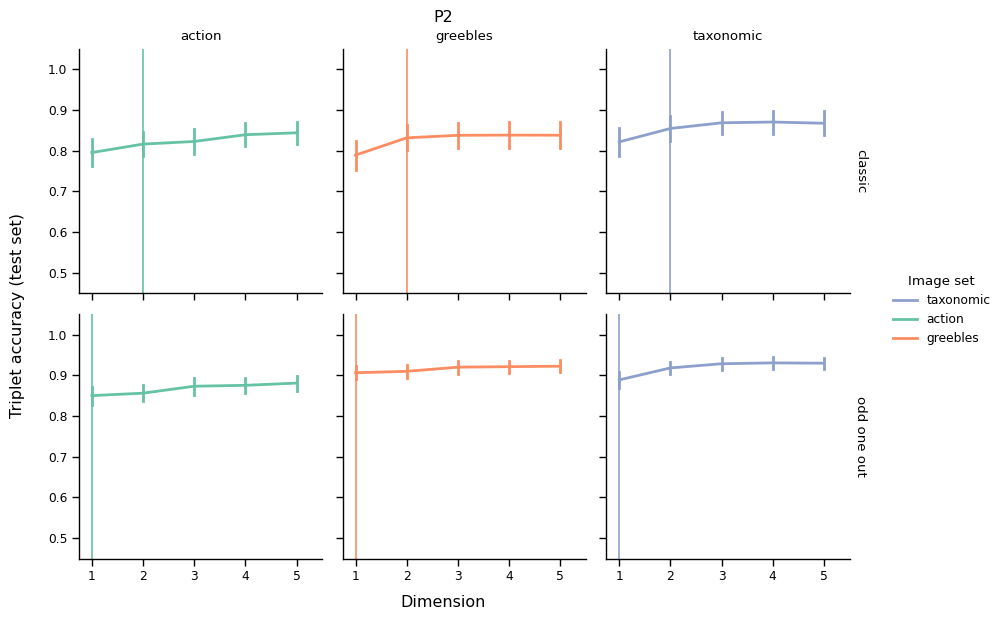

In [10]:
g = sns.FacetGrid(
    data=triplet_acc_all_plot, row="task", col='image_set', 
    hue="image_set", palette=palette_imset,
    row_order = ['classic', 'odd one out'],
    col_order = ['action', 'greebles', 'taxonomic'],
    height=3, margin_titles=True, aspect=1,
    sharey=True, sharex=True,
)

g.map(sns.lineplot, 'dimension', 'triplet accuracy', err_style="bars", errorbar=("sd", 2), 
      linewidth=2, err_kws={'elinewidth': 2})

for (task, imset), ax in g.axes_dict.items():
    ## reading final dimensionality 
    recalculated = read_recalculated(obs, task, image_set)
    new_dimension = recalculated['estimated_dimension']
    
    # drawing vertical dashed line with NEW estimated dimensionality
    ax.axvline(x=new_dimension, color=palette_imset[imset], alpha=1, zorder=-1,
             linestyle='-')
   

g.set(ylim = (0.45, 1.05), xlim=(0.75, 5.5))
g.add_legend(title = 'Image set')
g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.set_ylabels('')
g.set_xlabels('')
g.fig.suptitle(obs, x=0.45, y=1.01)
g.fig.supylabel('Triplet accuracy (test set)')
g.fig.supxlabel('Dimension', x=0.45)
g.savefig(f"../plots/triplet_accuracy_vs_dimensions_{obs}.pdf")